# بيّن: متى يرتفع التبرع في منصة إحسان؟

**فريق بيّن** · مسابقة تحليل البيانات

**السؤال:** متى يرتفع عدد المتبرعين في اليوم؟ وهل يرتبط الارتفاع بالمواسم الدينية، أو بيوم الأسبوع، أو بمواعيد صرف الرواتب والمعاشات والدعم؟

**القرار الذي ندعمه:** ترشيح فترات لاختبار الحملات الإعلانية (لا تحديد «أفضل وقت للإعلان»، لأن البيانات لا تتضمن أي معلومات عن الإعلانات).

**طريقة التشغيل:** `Runtime → Restart session and run all`. في Colab تنسخ الخلية الأولى المستودع (فيه الملف النظيف)؛ ومن جذر المستودع تعمل مباشرة. الكود المنطقي في الحزمة `bayyin/` (وحدة لكل غرض)، وهذا الدفتر يحكي الخطوات ويعرض النتائج. كل الجداول تُحفظ في `outputs/tables/` والرسوم في `outputs/figures/`. ويمكن تشغيل التحليل كله بأمر واحد: `python -m bayyin`.

## تهيئة
نجعل الحزمة `bayyin` قابلة للاستيراد، ثم نستورد ما نحتاجه مرة واحدة لكل الدفتر.

In [1]:
# SETUP - in Colab, clone the repository (the cleaned data is inside it); from the repo root nothing is needed
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("bayyin").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/maramsaleh-anz/BayHack", "BayHack"], check=True)
    os.chdir("BayHack")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hijridate"], check=True)

import matplotlib.pyplot as plt
import pandas as pd

from bayyin import data, hours, models, paydays, pipeline, plots, robustness
from bayyin.config import FIG_DIR, FORECAST_HORIZON, INPUT_CSV, OUT_DIR, TABLE_DIR
from bayyin.forecast import run_forecast

## تهيئة
نجعل الحزمة `bayyin` قابلة للاستيراد، ثم نستورد ما نحتاجه مرة واحدة لكل الدفتر.

In [2]:
# STEP 0 - Load the cleaned file (also checks that it is the final version)
raw = data.load_clean()
print(f"Input: {INPUT_CSV.name} ({INPUT_CSV.stat().st_size / 1e6:.1f} MB) | outputs go to {OUT_DIR.name}/")

Input: ehsan_rows_2021-04_2023-06.csv (15.0 MB) | outputs go to outputs/


## الخطوة 0: تحميل الملف النظيف
الملف ناتج دفتر التنظيف (الخلايا 1–8)، ونتحقق أنه النسخة النهائية قبل البدء.

In [3]:
# STEP 1 - Keep only the columns the analysis needs
analysis = data.select_columns(raw)
print(f"Rows: {len(analysis)} | columns: {raw.shape[1]} -> {analysis.shape[1]}")
analysis.head()

Rows: 40548 | columns: 45 -> 14


,RowID,UserID_clean,Gregorian_Date,Hijri_Year,Hijri_Month,Hijri_Month_Name,Hijri_Day,Hijri_Month_Complete,InitiativeName_clean,Amount_num,Recurring_01,flag_dup_extra,dup_group,dup_group_size
0,R05771,U5C2,2021-04-01,1442,8,شعبان,19,False,مشروع,5,0,False,NaN,1
1,R14199,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1
2,R14187,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1
3,R14180,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1
4,R14259,U9D9,2021-04-02,1442,8,شعبان,20,False,مشروع,10,0,False,NaN,1


## الخطوة 1: اختيار الأعمدة
نحتفظ بالأعمدة التي يحتاجها التحليل فقط، ونتحقق أن عدد الصفوف ومجموع المبالغ لم يتغيرا.

In [4]:
# STEP 2 - Remove automatic charges (Recurring_01 = 1): their time is set by the system, not the donor
analysis, excluded_recurring = data.drop_automatic_charges(analysis)
print(f"Removed automatic charges: {len(excluded_recurring)} rows ({excluded_recurring['Amount_num'].sum():,} SAR)")
print(f"Kept: {len(analysis)} rows | donors: {analysis['UserID_clean'].nunique()}")

Removed automatic charges: 10981 rows (96,125 SAR)
Kept: 29567 rows | donors: 1362


## الخطوة 2: استبعاد السحب التلقائي
التبرع الدوري يسحبه النظام في وقت يحدده هو، فلا يعكس قرار المتبرع. نحفظ المستبعد في جدول مستقل.

In [5]:
# STEP 3 - Merge duplicate copies (flag_dup_extra): one transaction per group, first row kept
analysis, excluded_duplicates = data.merge_duplicates(analysis)
print(f"Merged duplicate copies: {len(excluded_duplicates)} rows ({excluded_duplicates['Amount_num'].sum():,} SAR)")
print(f"Kept: {len(analysis)} rows | donors: {analysis['UserID_clean'].nunique()} | columns: {analysis.shape[1]}")

Merged duplicate copies: 45 rows (4,569 SAR)
Kept: 29522 rows | donors: 1362 | columns: 11


## الخطوة 3: دمج النسخ المكررة
السجلات المتطابقة في المتبرع والمبلغ والمبادرة والوقت تُعدّ عملية واحدة.

In [6]:
# STEP 4 - Donor-day table: one row per donor per day
donor_day = data.build_donor_day(analysis)
print(f"Donations: {len(analysis)} -> donor-days: {len(donor_day)} | donors: {donor_day['UserID_clean'].nunique()}")
donor_day.head()

Donations: 29522 -> donor-days: 17097 | donors: 1362


,UserID_clean,Gregorian_Date,Donations,Amount,Initiatives,Hijri_Year,Hijri_Month,Hijri_Month_Name,Hijri_Day,Hijri_Month_Complete
0,800U,2021-04-19,2,60,1,1442,9,رمضان,7,True
1,800U,2021-04-21,2,50,1,1442,9,رمضان,9,True
2,800U,2021-07-19,1,20,1,1442,12,ذو الحجة,9,True
3,800U,2022-04-11,2,70,2,1443,9,رمضان,10,True
4,8013,2021-05-07,1,21,1,1442,9,رمضان,25,True


## الخطوة 4: جدول متبرع-يوم
صف واحد لكل متبرع في كل يوم، لأن المقياس الأساسي هو **عدد المتبرعين المختلفين في اليوم**.

In [7]:
# STEP 5 - Daily table: one row per calendar day (days without data stay EMPTY, not 0)
daily = data.build_daily(donor_day, analysis)
print(f"Days: {len(daily)} | with data: {daily['has_data'].sum()} | without data: {(~daily['has_data']).sum()}")
print(f"Donors per day: mean {daily['Donors'].mean():.1f}, median {daily['Donors'].median():.0f}")
daily.head()

Days: 821 | with data: 811 | without data: 10
Donors per day: mean 21.1, median 16


,Gregorian_Date,Weekday,Hijri_Year,Hijri_Month,Hijri_Month_Name,Hijri_Day,Donors,Donations,Amount,has_data
0,2021-04-01,Thursday,1442,8,شعبان,19,1.0,1.0,5.0,True
1,2021-04-02,Friday,1442,8,شعبان,20,1.0,5.0,60.0,True
2,2021-04-03,Saturday,1442,8,شعبان,21,2.0,2.0,150.0,True
3,2021-04-04,Sunday,1442,8,شعبان,22,1.0,3.0,1100.0,True
4,2021-04-05,Monday,1442,8,شعبان,23,NaN,NaN,NaN,False


## الخطوة 5: الجدول اليومي
صف لكل يوم ميلادي مع التاريخ الهجري (أم القرى). الأيام بلا بيانات تُترك فارغة ولا تُحسب صفراً.

In [8]:
# STEP 6 - Payday calendar and the payday flags on the daily table (rules and overrides: bayyin/config.py)
payday_calendar = paydays.build_payday_calendar()
daily = paydays.add_payday_flags(daily, payday_calendar)

print("Paydays per program inside the period:")
print(paydays.paydays_inside(payday_calendar, daily).to_string(index=False))
print("Not covered: social security before June 2022 (no reliable historical dates found - no date assumed)")
payday_calendar.head(8)

Paydays per program inside the period:
   Program                                       Status  Paydays
citizen_10                                    announced        1
citizen_10                                         rule       26
day1_group check (weekend shift from secondary sources)        8
day1_group                                         rule       20
pension_25                                         rule       27
 salary_27                                         rule       27
Not covered: social security before June 2022 (no reliable historical dates found - no date assumed)


,Program,Month,Pay_Date,Weekday,Status,Source
0,salary_27,2021-03,2021-03-28,Sunday,rule,baseline rule
1,pension_25,2021-03,2021-03-25,Thursday,rule,baseline rule
2,citizen_10,2021-03,2021-03-10,Wednesday,rule,baseline rule
3,day1_group,2021-03,2021-03-01,Monday,rule,baseline rule
4,salary_27,2021-04,2021-04-27,Tuesday,rule,baseline rule
5,pension_25,2021-04,2021-04-25,Sunday,rule,baseline rule
6,citizen_10,2021-04,2021-04-11,Sunday,rule,baseline rule
7,day1_group,2021-04,2021-04-01,Thursday,rule,baseline rule


## الخطوة 6: تقويم الصرف
القواعد الأساسية (الرواتب 27، التقاعد 25، حساب المواطن 10، برامج أول الشهر 1) مع ترحيلها عند الجمعة والسبت، ويُقدَّم عليها أي إعلان رسمي. نافذة الصرف = يوم الصرف + 3 أيام، وحُددت قبل رؤية النتائج.

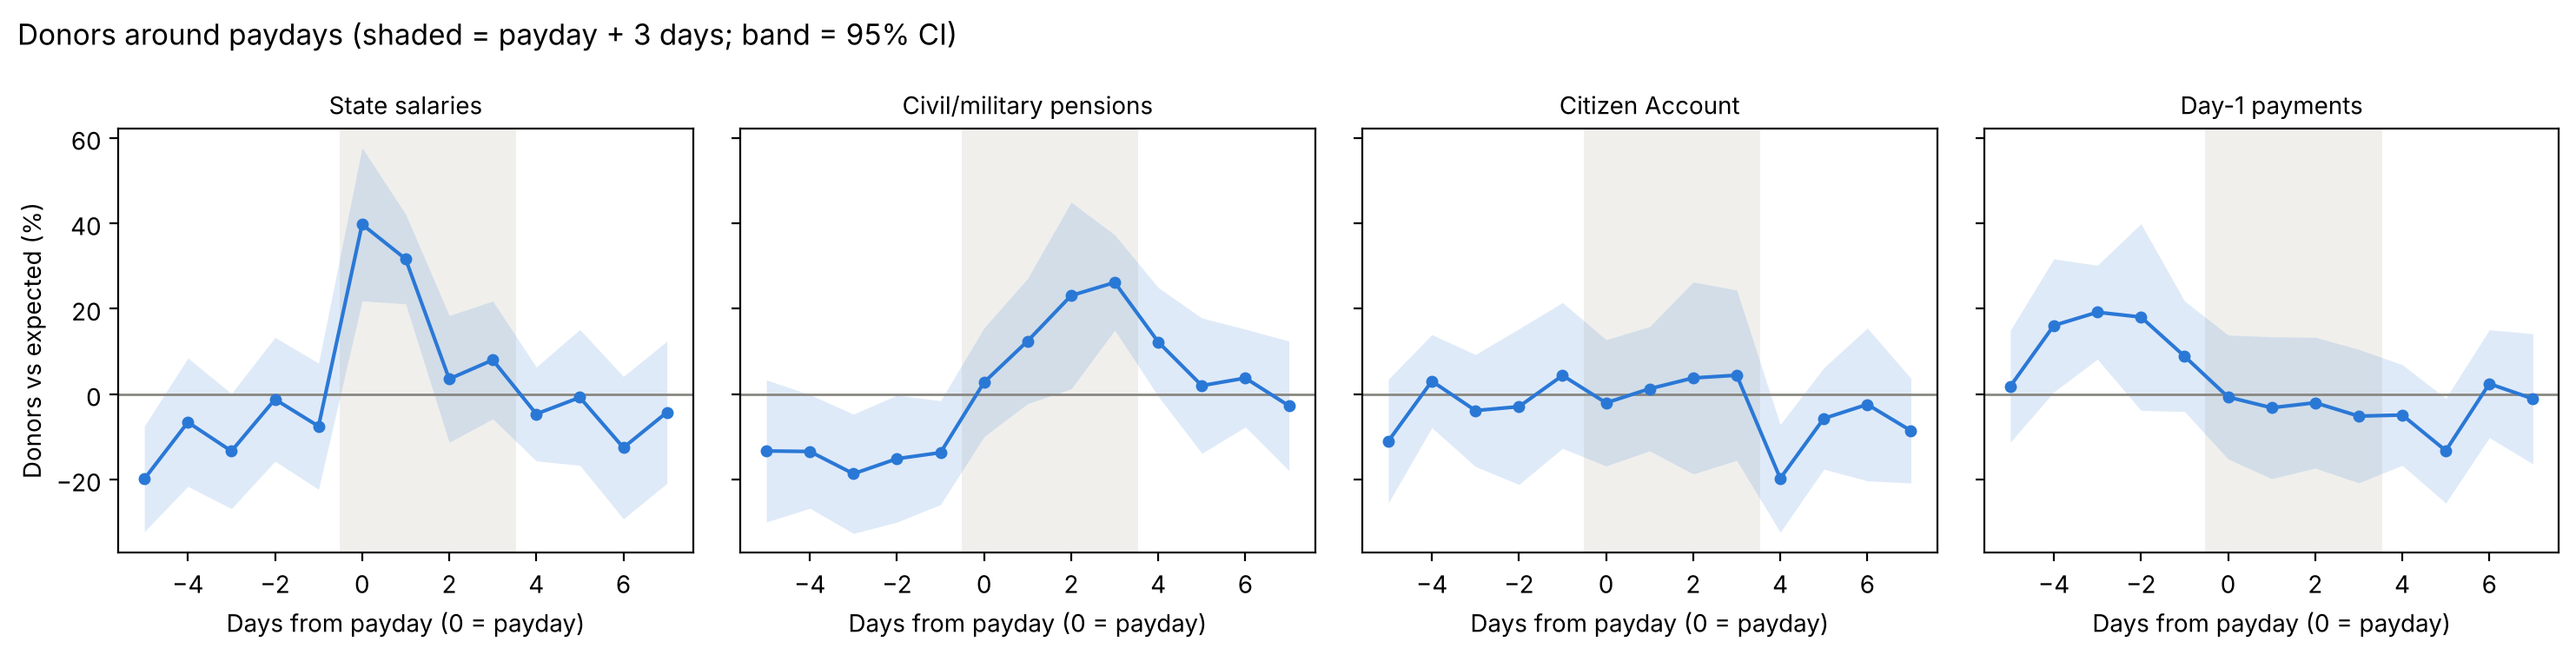

,Payment,Window_days,Overlap_with_salary_window_%,Change_%,CI_low_%,CI_high_%,p_value,Paydays,Event_view_%,Event_CI_low_%,Conclusion
0,State salaries (27th),108,100,25.6,11.7,41.2,0.0001,27,20.8,10.7,Clear rise
1,Civil/military pensions (25th),108,51,17.8,7.8,28.7,0.0003,27,16.1,6.0,"Rise, but mostly the salary days (overlap)"
2,Citizen Account (10th),107,0,12.6,1.3,25.2,0.0278,27,1.2,-13.9,Not confirmed by the event view
3,"Day-1 payments (GOSI pensions, Saned, social s...",109,14,8.4,-1.3,19.2,0.0930,28,-3.6,-15.8,No clear rise


In [9]:
# ANALYSIS 1 - Do donors rise after paydays?
#   Association in this sample, not proof of cause, and not proof that donors are employees or retirees.
daily = models.add_season_flags(daily)  # one 0/1 column per religious season (rules: bayyin/config.py)
payday_analysis = models.analyze_paydays(daily, payday_calendar)
plots.plot_paydays(payday_analysis)
plt.show()
payday_analysis.results

## تحليل 1: هل يرتفع التبرع بعد أيام الصرف؟
نموذج بواسون يضبط يوم الأسبوع ونمو العينة والمواسم، مع أخطاء HAC. وفحص ثانٍ: «عرض الحدث» حول كل يوم صرف. لا نحكم بـ«ارتفاع واضح» إلا إذا اتفقت الطريقتان.

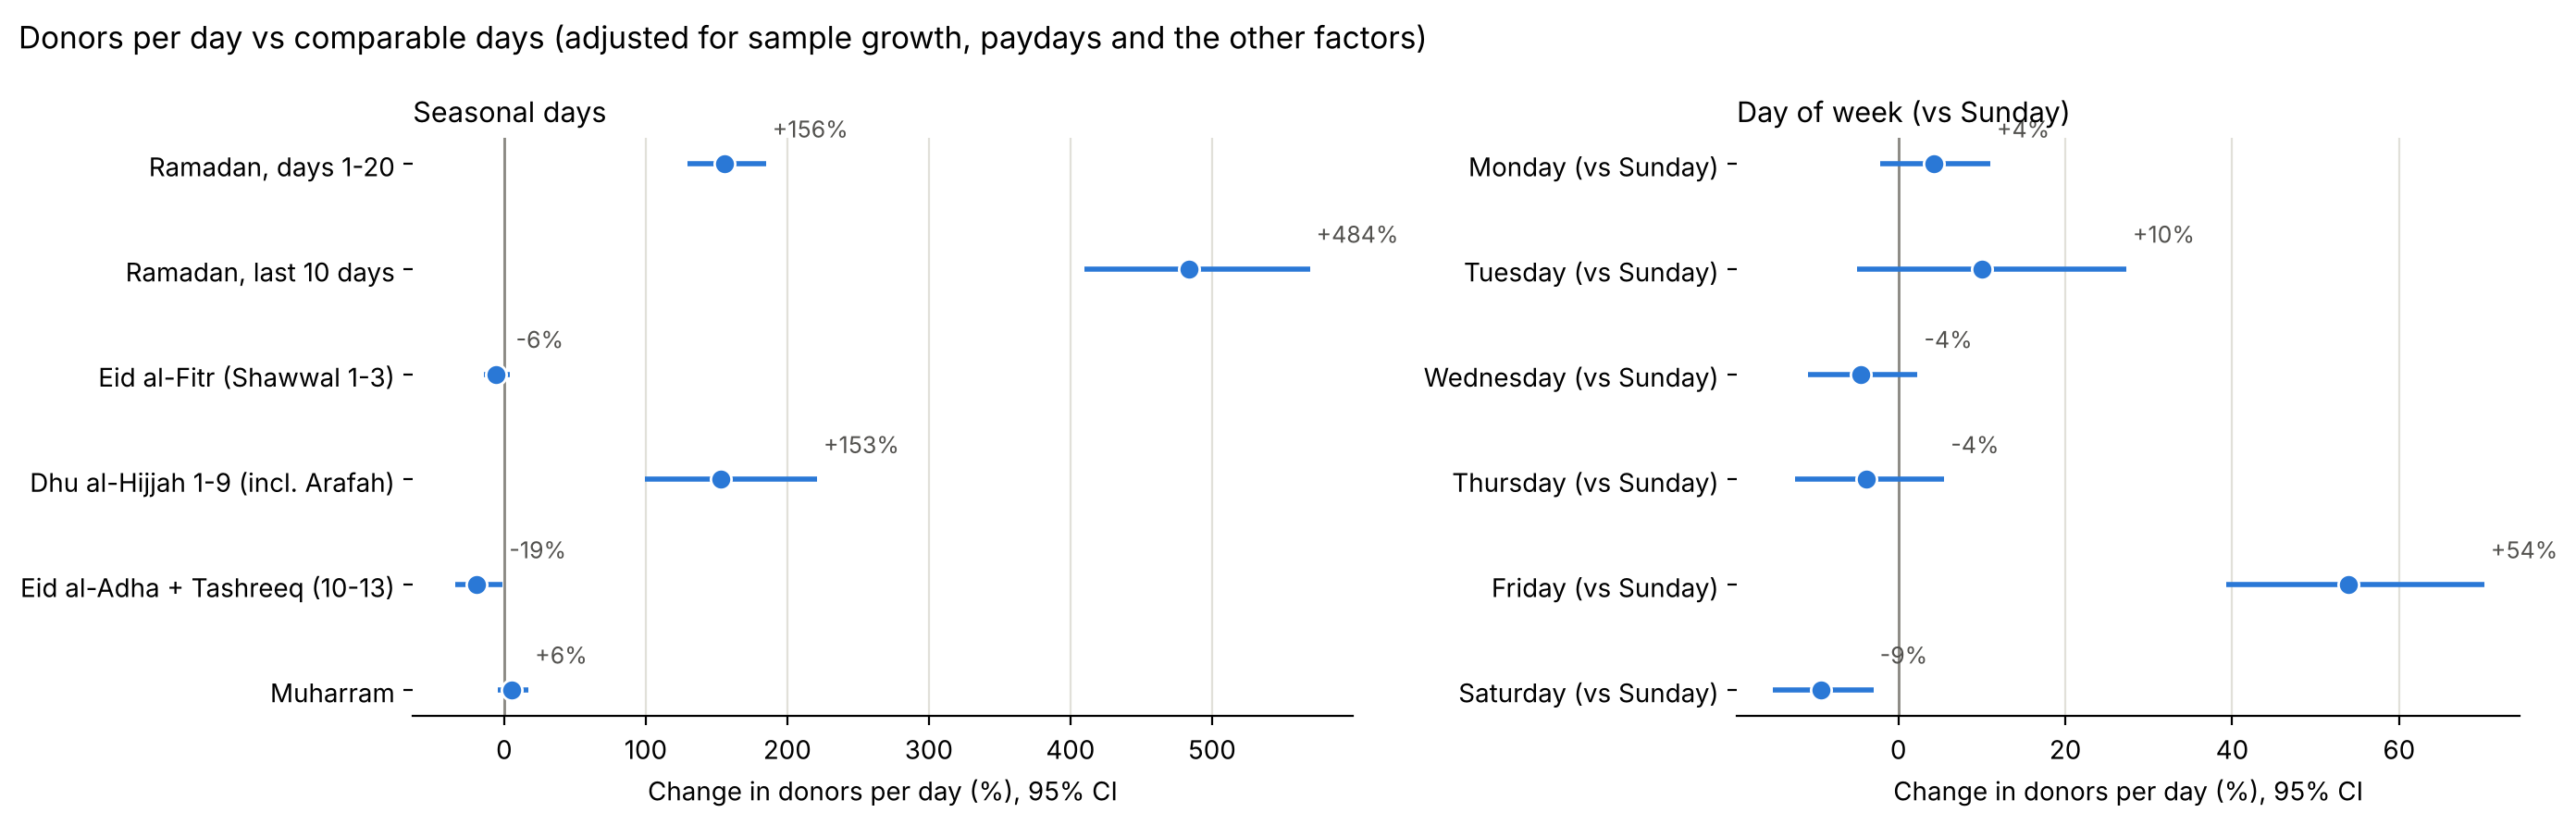

Days used: 811 | Friday above the average of the other 6 days in 96 of 109 full weeks


,Factor,Days,Change_%,CI_low_%,CI_high_%,p_value,Conclusion,Higher_than_ordinary_days_before
0,"Ramadan, days 1-20",60,155.6,129.4,184.9,0.0000,Clear rise,2 of 2
1,"Ramadan, last 10 days",29,484.0,409.7,569.1,0.0000,Clear rise,2 of 2
2,Eid al-Fitr (Shawwal 1-3),9,-5.7,-14.3,3.7,0.2231,No clear difference,1 of 2
3,Dhu al-Hijjah 1-9 (incl. Arafah),27,153.1,99.5,221.0,0.0000,Clear rise,3 of 3
4,Eid al-Adha + Tashreeq (10-13),11,-19.4,-34.3,-1.0,0.0397,Not consistent (model and check disagree),2 of 3
5,Muharram,59,5.6,-4.8,17.2,0.2998,No clear difference,2 of 2


,Factor,Days,Change_%,CI_low_%,CI_high_%,p_value,Conclusion
0,Monday (vs Sunday),116,4.2,-2.2,11.0,0.2051,No clear difference
1,Tuesday (vs Sunday),114,10.0,-5.0,27.3,0.2027,No clear difference
2,Wednesday (vs Sunday),115,-4.5,-10.8,2.3,0.1936,No clear difference
3,Thursday (vs Sunday),116,-3.9,-12.4,5.5,0.4032,No clear difference
4,Friday (vs Sunday),118,53.9,39.3,70.2,0.0000,Clear rise
5,Saturday (vs Sunday),117,-9.3,-15.1,-3.0,0.0044,Clear drop


In [10]:
# ANALYSIS 2 - Ramadan, seasonal days and Friday: do donors rise?
season_analysis = models.analyze_seasons(daily)
plots.plot_seasons_friday(season_analysis)
plt.show()
print(f"Days used: {season_analysis.days_used} | {season_analysis.friday_weeks}")
display(season_analysis.seasons)
display(season_analysis.weekdays)

## تحليل 2: المواسم ويوم الجمعة
نموذج واحد يضبط كل العوامل معاً. الفحص الثاني للمواسم: مقارنة بآخر 28 يوماً عادياً قبل كل موسم؛ وللجمعة: مقارنتها بباقي أيام أسبوعها.

In [11]:
# RESULT - Candidate periods for testing campaigns (built from the two analyses above, not typed by hand)
candidates, not_supported = models.rank_candidates(season_analysis.seasons, season_analysis.weekdays,
                                                   payday_analysis.results)
print(f"Candidate periods (clear rise): {len(candidates)} | no clear evidence: {len(not_supported)}")
display(candidates)
display(not_supported)

Candidate periods (clear rise): 5 | no clear evidence: 11


,Rank,Type,Factor,Change_%,CI_low_%,CI_high_%,Conclusion
0,1,Season,"Ramadan, last 10 days",484.0,409.7,569.1,Clear rise
1,2,Season,"Ramadan, days 1-20",155.6,129.4,184.9,Clear rise
2,3,Season,Dhu al-Hijjah 1-9 (incl. Arafah),153.1,99.5,221.0,Clear rise
3,4,Day of week,Friday (vs Sunday),53.9,39.3,70.2,Clear rise
4,5,Payday (payday + 3 days),State salaries (27th),25.6,11.7,41.2,Clear rise


,Type,Factor,Change_%,CI_low_%,CI_high_%,Conclusion
0,Season,Eid al-Fitr (Shawwal 1-3),-5.7,-14.3,3.7,No clear difference
1,Season,Eid al-Adha + Tashreeq (10-13),-19.4,-34.3,-1.0,Not consistent (model and check disagree)
2,Season,Muharram,5.6,-4.8,17.2,No clear difference
3,Day of week,Monday (vs Sunday),4.2,-2.2,11.0,No clear difference
4,Day of week,Tuesday (vs Sunday),10.0,-5.0,27.3,No clear difference
5,Day of week,Wednesday (vs Sunday),-4.5,-10.8,2.3,No clear difference
6,Day of week,Thursday (vs Sunday),-3.9,-12.4,5.5,No clear difference
7,Day of week,Saturday (vs Sunday),-9.3,-15.1,-3.0,Clear drop
8,Payday (payday + 3 days),Civil/military pensions (25th),17.8,7.8,28.7,"Rise, but mostly the salary days (overlap)"
9,Payday (payday + 3 days),Citizen Account (10th),12.6,1.3,25.2,Not confirmed by the event view


## النتيجة: الفترات المرشّحة
تُبنى آلياً من التحليلين أعلاه (لا تُكتب يدوياً)، مرتبة حسب حجم الارتفاع.

In [12]:
# ROBUSTNESS - Re-run the main model 9 times, changing ONE choice each time (variants: bayyin/config.py)
robustness_table, robustness_summary = robustness.run_robustness(daily, donor_day, analysis, excluded_duplicates, candidates)
print(robustness_summary.to_string(index=False))

                          Factor  Main_change_pct  Min_change_pct  Max_change_pct Survived
           Ramadan, last 10 days            484.0           453.2           881.4   9 of 9
              Ramadan, days 1-20            155.6           147.4           219.7   9 of 9
Dhu al-Hijjah 1-9 (incl. Arafah)            153.1           135.5           394.9   9 of 9
              Friday (vs Sunday)             53.9            50.8            70.6   9 of 9
           State salaries (27th)             25.6            21.3            66.4   9 of 9


## اختبار الثبات
نعيد النموذج 9 مرات ونغيّر في كل مرة اختياراً واحداً: المقياس (3)، ونافذة الراتب (3)، ومرونة الاتجاه الزمني (2)، وبداية الفترة (1). تبقى الفترة مرشّحة فقط إذا بقي ارتفاعها واضحاً في كل المرات.

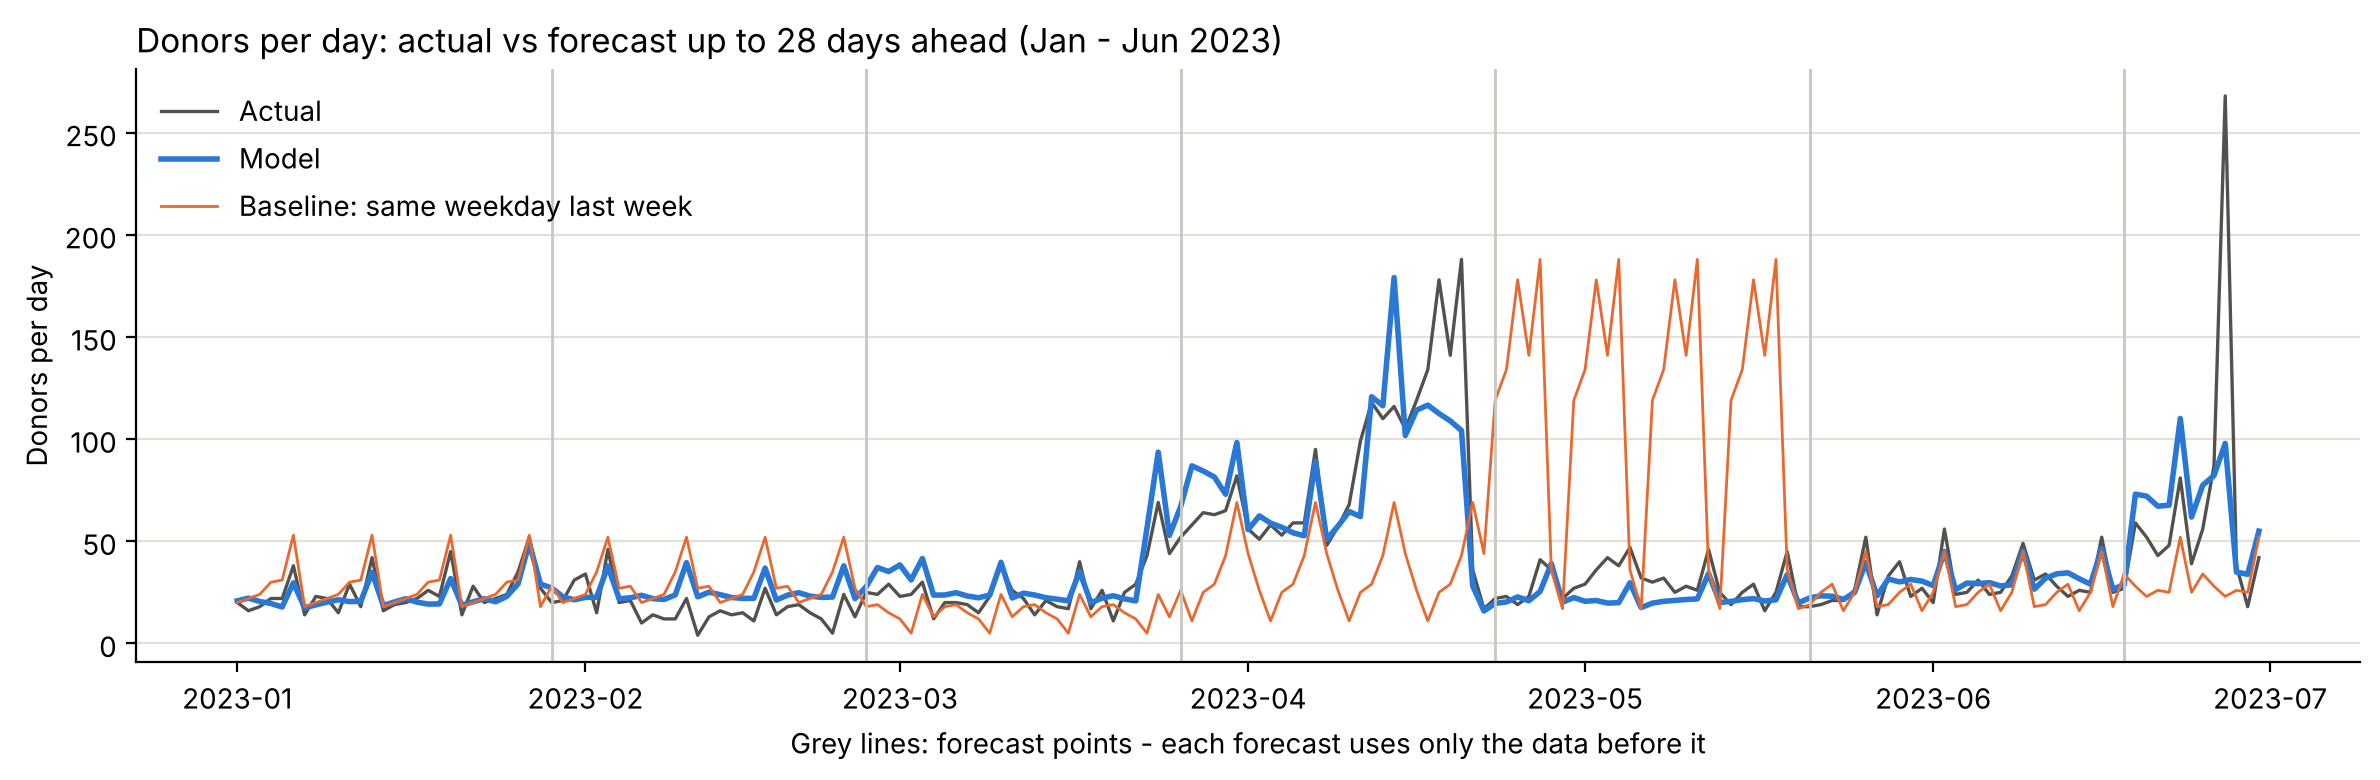

Test days: 181 in 7 blocks | model error 62% lower than the 28-day mean


,Model,Mean_last_28,Same_weekday_last_week,Days
All test days,9.8,25.6,30.8,181
Season days,20.0,52.4,49.8,44
Ordinary days,6.5,16.9,24.7,137


In [13]:
# FORECAST - Predict donors per day up to 28 days ahead
forecast = run_forecast(daily)
plots.plot_forecast(forecast, FORECAST_HORIZON)
plt.show()
print(f"Test days: {len(forecast.forecast)} in {len(forecast.block_starts)} blocks | "
      f"model error {forecast.improvement:.0%} lower than the 28-day mean")
forecast.errors

## نموذج التوقع
يتوقع عدد المتبرعين حتى 28 يوماً مقدماً من التقويم والمستوى المعتاد قبل شهر. نختبره على يناير–يونيو 2023 في كتل من 28 يوماً، وكل توقع يستخدم البيانات السابقة له فقط، ونقارنه بطريقتين بسيطتين.

### هل يختار النموذج الأيام الصحيحة؟
نرتّب أيام الاختبار (181 يوماً) بكل طريقة، ونحسب كم نسبة من المتبرعين وقعت في أعلى 10% و20% من الأيام. المقارنة بثلاث طرق: «المواسم فقط» (ترتيب من التقويم الهجري وحده)، و«نفس اليوم الأسبوع الماضي»، والاختيار العشوائي (10% و20% بالتعريف)، وسقفها «لو عرفنا المستقبل». الأهم صفّا «الأيام العادية»: هناك نرى هل يضيف النموذج شيئاً غير المواسم.

In [14]:
# FORECAST CHECK - share of donors that fall in the top 10% / 20% of days, as ranked by each method
forecast.capture

,Days_group,Top_days,Days,Perfect_hindsight,Model,Seasons_only,Same_weekday_last_week,Random
0,All test days,10%,181,31.3,30.7,26.1,7.5,9.9
1,All test days,20%,181,46.2,45.4,44.6,20.8,19.9
2,Ordinary days,10%,137,19.2,15.6,10.2,11.8,10.2
3,Ordinary days,20%,137,32.6,28.4,19.7,24.3,19.7


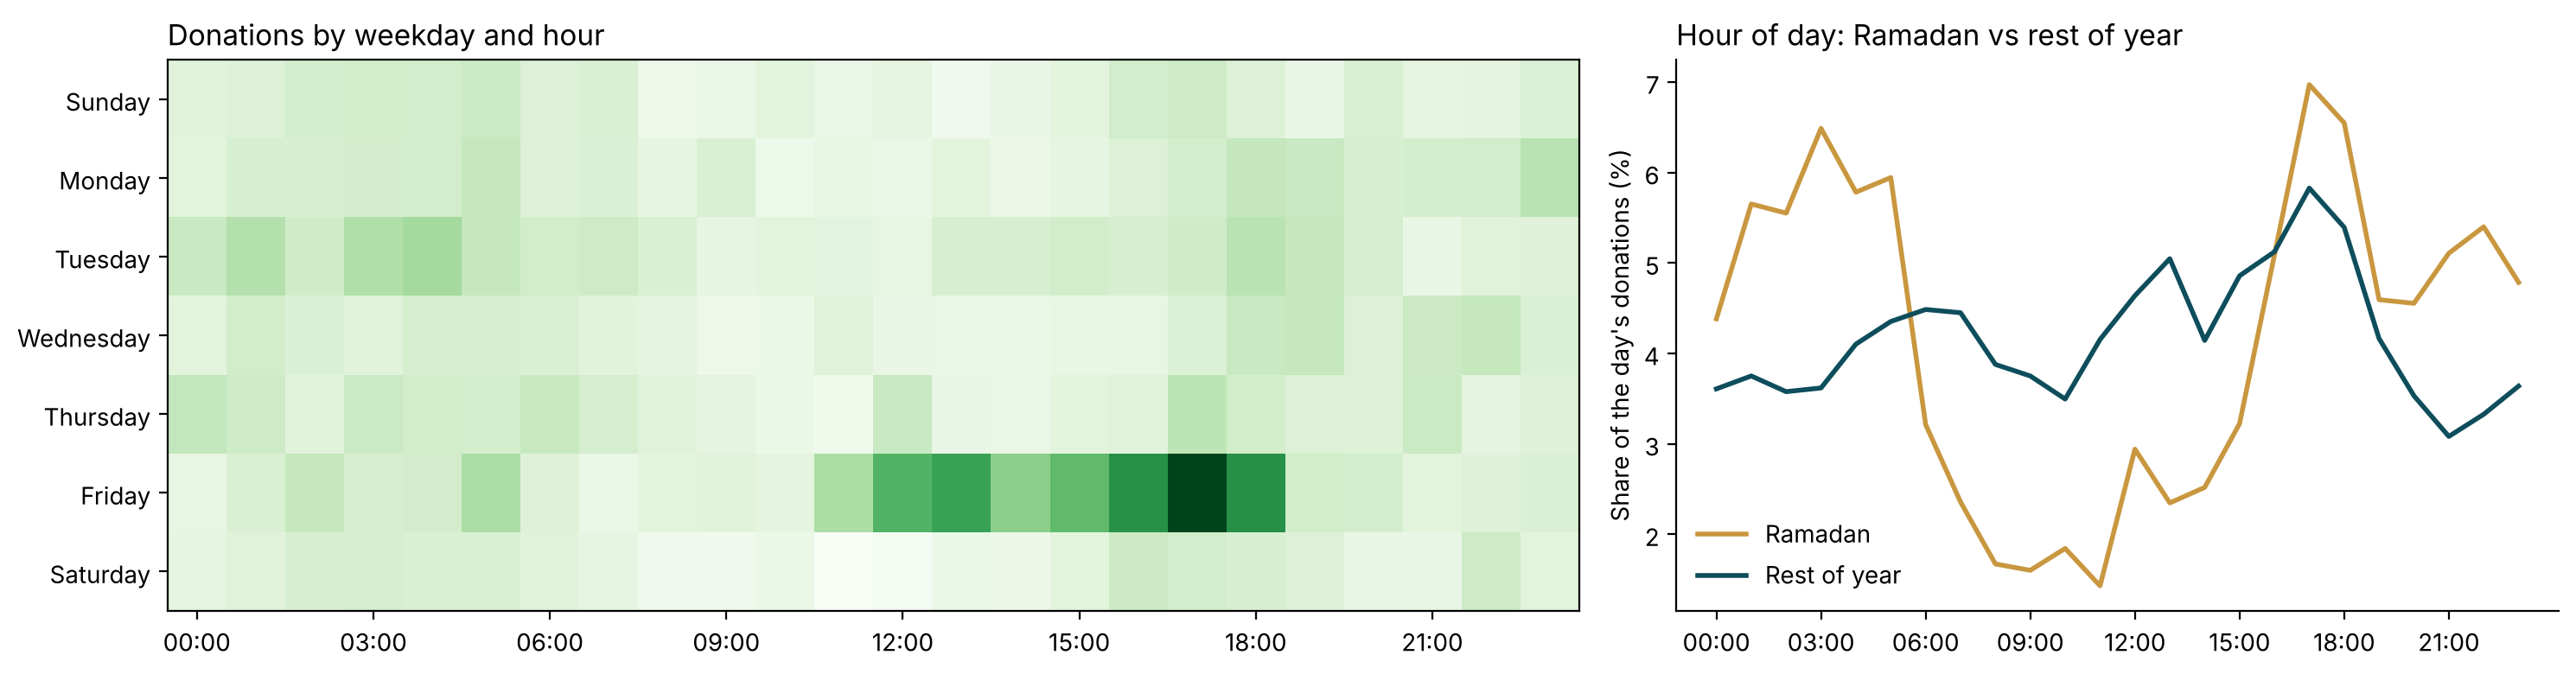

Busiest hour overall: 17:00 (6.2% of donations)


,Weekday,Hour,Donations
0,Friday,17,676
1,Friday,18,511
2,Friday,16,506
3,Friday,13,468
4,Friday,12,421


In [15]:
# HOURS (descriptive) - When in the day do donors give? Same donations as the analysis (no auto-charges, no duplicates)
hour_analysis = hours.analyze_hours(raw, analysis)
plots.plot_hours(hour_analysis)
plt.show()
print(f"Busiest hour overall: {hour_analysis.busiest_hour:02d}:00 ({hour_analysis.busiest_share:.1%} of donations)")
hour_analysis.top_slots

## ساعة اليوم (تحليل وصفي)
متى في اليوم يتبرع الناس؟ الأوقات كما سُجلت في المصدر، والمنطقة الزمنية غير مذكورة (نمط السحور والإفطار في رمضان يرجّح توقيت السعودية).

In [16]:
# SAVE - Write every result table to outputs/tables (the figures were saved when they were drawn)
tables = pipeline.collect_tables(
    candidates=candidates, not_supported=not_supported, payday=payday_analysis, seasons=season_analysis,
    calendar=payday_calendar, robustness_table=robustness_table, robustness_summary=robustness_summary,
    forecast=forecast, hours=hour_analysis, excluded_recurring=excluded_recurring, excluded_duplicates=excluded_duplicates)
pipeline.save_tables(tables)
print(f"Saved {len(tables)} tables to {TABLE_DIR.name}/ and figures to {FIG_DIR.name}/ (no donor IDs in any saved file)")

if "google.colab" in sys.modules:  # download everything in one file
    import shutil
    from google.colab import files
    shutil.make_archive("outputs", "zip", OUT_DIR)
    files.download("outputs.zip")

Saved 15 tables to tables/ and figures to figures/ (no donor IDs in any saved file)
